# Tugas - Medical Cost Prediction

| Nama | NRP |
|------|-----|
| Lioneil Diyoel Trystan Tikupadang | 5054251037 |

## Deskripsi Tugas

Pada tugas ini, kita akan menggunakan Medical Cost Personal Dataset dari Kaggle.

Dataset:
- https://www.kaggle.com/mirichoi0218/insurance

Target yang diprediksi adalah `charges`.

Model yang digunakan:
1. Linear Regression
2. Polynomial Regression
3. Ridge Regression
4. Lasso Regression
5. Decision Tree Regressor
6. Support Vector Regression


# 1. Persiapan Dataset dan Eksplorasi Awal

In [65]:
# Import library yang dibutuhkan.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV
from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

RANDOM_STATE = 42


In [66]:
# Load dataset.
# Sesuaikan nama file dengan file dataset yang digunakan.
df = pd.read_csv("insurance.csv")
df.shape

(1338, 7)

In [67]:
# Tampilkan beberapa baris pertama dataset.
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [68]:
# Tampilkan informasi dataset.
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB


In [69]:
# Periksa missing value.
print("Jumlah missing value:")
print(df.isnull().sum())
print("\nJumlah duplikat:", df.duplicated().sum())

Jumlah missing value:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

Jumlah duplikat: 1


In [70]:
# Tampilkan statistik deskriptif fitur numerik.
df.describe()


,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [71]:
# Tampilkan jumlah nilai pada setiap fitur kategorikal.
for col in ["sex", "smoker", "region"]:
    print(f"\n{col}:")
    print(df[col].value_counts())



sex:
sex
male      676
female    662
Name: count, dtype: int64

smoker:
smoker
no     1064
yes     274
Name: count, dtype: int64

region:
region
southeast    364
southwest    325
northwest    325
northeast    324
Name: count, dtype: int64


## Lakukan Exploratory Data Analysis (EDA) sederhana yang diperlukan.


# 2. Preprocessing

Pisahkan fitur numerik dan kategorikal. Gunakan OneHotEncoder untuk fitur kategorikal.

Model Linear Regression, Polynomial Regression, Ridge, Lasso, dan SVR menggunakan data yang telah di-scaling. Decision Tree Regressor tidak memerlukan scaling.


In [72]:
# Pisahkan fitur (X) dan target (y).
X = df.drop(columns="charges")
y = df["charges"]

In [73]:
# Identifikasi kolom numerik dan kategorikal.
numeric_features = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_features = X.select_dtypes(include=["object", "str", "category"]).columns.tolist()

print("Fitur numerik     :", numeric_features)
print("Fitur kategorikal :", categorical_features)

Fitur numerik     : ['age', 'bmi', 'children']
Fitur kategorikal : ['sex', 'smoker', 'region']


In [74]:
# Bagi data menjadi train set dan test set.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)

print("Train:", X_train.shape)
print("Test :", X_test.shape)

Train: (1070, 6)
Test : (268, 6)


In [75]:
# Buat preprocessing untuk fitur numerik dan kategorikal.
preprocessor_unscaled = ColumnTransformer(
    transformers=[
        ("num", "passthrough", numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_features),
    ]
)

def regression_metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "R²": r2_score(y_true, y_pred),
    }

# 3. Eksperimen Model

## 3.1 Linear Regression

Bangun model Linear Regression menggunakan data hasil preprocessing.


In [76]:
# Inisialisasi dan latih Linear Regression.
linear_model = Pipeline([
    ("preprocessor", preprocessor_unscaled),
    ("scaler", StandardScaler()),
    ("model", LinearRegression())
])
linear_model.fit(X_train, y_train);

In [77]:
# Lakukan prediksi pada test set.
y_pred_linear = linear_model.predict(X_test)
print(regression_metrics(y_test, y_pred_linear))

{'MAE': 4181.194473753652, 'MSE': 33596915.851361476, 'RMSE': np.float64(5796.284659276274), 'R²': 0.7835929767120722}


## 3.2 Polynomial Regression

Gunakan PolynomialFeatures. Tentukan degree berdasarkan eksperimen.


In [78]:
# Buat fitur polynomial dan latih model.
X_train_poly, X_val_poly, y_train_poly, y_val_poly = train_test_split(
    X_train, y_train, test_size=0.2, random_state=RANDOM_STATE
)

poly_results = []
for degree in [1, 2, 3]:
    poly_model = Pipeline([
        ("preprocessor", preprocessor_unscaled),
        ("poly", PolynomialFeatures(degree=degree, include_bias=False)),
        ("scaler", StandardScaler()),
        ("model", LinearRegression())
    ])
    poly_model.fit(X_train_poly, y_train_poly)
    pred_val = poly_model.predict(X_val_poly)
    poly_results.append({
        "degree": degree,
        "Validation RMSE": np.sqrt(mean_squared_error(y_val_poly, pred_val))
    })

poly_results_df = pd.DataFrame(poly_results).sort_values("Validation RMSE")
display(poly_results_df)

best_degree = int(poly_results_df.iloc[0]["degree"])
print("Degree terbaik berdasarkan validation RMSE:", best_degree)

polynomial_model = Pipeline([
    ("preprocessor", preprocessor_unscaled),
    ("poly", PolynomialFeatures(degree=best_degree, include_bias=False)),
    ("scaler", StandardScaler()),
    ("model", LinearRegression())
]);
polynomial_model.fit(X_train, y_train);

,degree,Validation RMSE
1,2,5431.320544
2,3,5508.430962
0,1,6602.039502


Degree terbaik berdasarkan validation RMSE: 2


In [79]:
# Lakukan prediksi pada test set.
y_pred_poly = polynomial_model.predict(X_test)
print(regression_metrics(y_test, y_pred_poly))

{'MAE': 2729.5001336394475, 'MSE': 20712805.987918362, 'RMSE': np.float64(4551.132385233192), 'R²': 0.8665830903164841}


## 3.3 Ridge Regression

Gunakan Ridge Regression. Tentukan nilai alpha berdasarkan eksperimen.


In [80]:
# Inisialisasi dan latih Ridge Regression.
ridge_model = Pipeline([
    ("preprocessor", preprocessor_unscaled),
    ("scaler", StandardScaler()),
    ("model", RidgeCV(
        alphas=[0.01, 0.1, 1.0, 10.0, 100.0],
        cv=5,
        scoring="neg_mean_squared_error"
    ))
])

ridge_model.fit(X_train, y_train);
print("Alpha Ridge terpilih:", ridge_model.named_steps["model"].alpha_)

Alpha Ridge terpilih: 10.0


In [81]:
# Lakukan prediksi pada test set.
y_pred_ridge = ridge_model.predict(X_test)
print(regression_metrics(y_test, y_pred_ridge))

{'MAE': 4187.357453462216, 'MSE': 33641733.793129735, 'RMSE': np.float64(5800.149462999185), 'R²': 0.78330429195866}


## 3.4 Lasso Regression

Gunakan Lasso Regression. Tentukan nilai alpha berdasarkan eksperimen.


In [82]:
# Inisialisasi dan latih Lasso Regression.
lasso_model = Pipeline([
    ("preprocessor", preprocessor_unscaled),
    ("scaler", StandardScaler()),
    ("model", LassoCV(
        cv=5,
        max_iter=100000
    ))
])

lasso_model.fit(X_train, y_train);
print("Alpha Lasso terpilih:", lasso_model.named_steps["model"].alpha_)

Alpha Lasso terpilih: 115.53731053498032


In [83]:
# Lakukan prediksi pada test set.
y_pred_lasso = lasso_model.predict(X_test)
print(regression_metrics(y_test, y_pred_lasso))

{'MAE': 4202.0129205506455, 'MSE': 34010427.9634342, 'RMSE': np.float64(5831.846016780124), 'R²': 0.7809294308775954}


## 3.5 Decision Tree Regressor

Gunakan Decision Tree Regressor. Eksperimen dapat dilakukan pada `max_depth` dan `min_samples_leaf`.


In [84]:
# Inisialisasi dan latih Decision Tree Regressor.
X_train_tree, X_val_tree, y_train_tree, y_val_tree = train_test_split(
    X_train, y_train, test_size=0.2, random_state=RANDOM_STATE
)

tree_candidates = [
    (2, 5), (4, 1), (4, 5), (6, 1), (6, 5), (8, 5), (None, 5)
]
tree_results = []

for max_depth, min_samples_leaf in tree_candidates:
    candidate = Pipeline([
        ("preprocessor", preprocessor_unscaled),
        ("model", DecisionTreeRegressor(
            criterion="squared_error",
            max_depth=max_depth,
            min_samples_leaf=min_samples_leaf,
            random_state=RANDOM_STATE
        ))
    ])
    candidate.fit(X_train_tree, y_train_tree)
    pred_val = candidate.predict(X_val_tree)
    tree_results.append({
        "max_depth": max_depth,
        "min_samples_leaf": min_samples_leaf,
        "Validation RMSE": np.sqrt(mean_squared_error(y_val_tree, pred_val))
    })

tree_results_df = pd.DataFrame(tree_results).sort_values("Validation RMSE")
display(tree_results_df)

best_tree_params = tree_results_df.iloc[0]
best_max_depth = best_tree_params["max_depth"]
best_min_samples_leaf = int(best_tree_params["min_samples_leaf"])

print("Parameter terbaik:")
print("max_depth =", best_max_depth)
print("min_samples_leaf =", best_min_samples_leaf)

decision_tree_model = Pipeline([
    ("preprocessor", preprocessor_unscaled),
    ("model", DecisionTreeRegressor(
        criterion="squared_error",
        max_depth=None if pd.isna(best_max_depth) else int(best_max_depth),
        min_samples_leaf=best_min_samples_leaf,
        random_state=RANDOM_STATE
    ))
])
decision_tree_model.fit(X_train, y_train);

,max_depth,min_samples_leaf,Validation RMSE
1,4.0,1,5324.785392
2,4.0,5,5324.785392
3,6.0,1,5571.642253
4,6.0,5,5632.107212
6,NaN,5,5718.193718
5,8.0,5,5724.007941
0,2.0,5,5745.256394


Parameter terbaik:
max_depth = 4.0
min_samples_leaf = 1


In [85]:
# Lakukan prediksi pada test set.
y_pred_tree = decision_tree_model.predict(X_test)
print(regression_metrics(y_test, y_pred_tree))

{'MAE': 2697.76543053848, 'MSE': 21093484.004597444, 'RMSE': np.float64(4592.764309715603), 'R²': 0.8641310379678357}


## 3.6 Support Vector Regression

Gunakan SVR dengan data yang telah di-scaling. Tentukan parameter berdasarkan eksperimen.


In [86]:
# Inisialisasi dan latih SVR.
X_train_svr, X_val_svr, y_train_svr, y_val_svr = train_test_split(
    X_train, y_train, test_size=0.2, random_state=RANDOM_STATE
)

svr_candidates = [
    (10, "scale", 0.1),
    (100, "scale", 0.1),
    (1000, "scale", 0.1),
    (100, 0.01, 0.1),
    (100, 0.1, 0.1),
    (1000, 0.01, 0.1),
    (1000, 0.1, 0.1),
    (100, "scale", 0.5),
    (1000, "scale", 0.5)
]
svr_results = []

for C, gamma, epsilon in svr_candidates:
    candidate = Pipeline([
        ("preprocessor", preprocessor_unscaled),
        ("scaler", StandardScaler()),
        ("model", SVR(
            kernel="rbf",
            C=C,
            gamma=gamma,
            epsilon=epsilon
        ))
    ])
    candidate.fit(X_train_svr, y_train_svr)
    pred_val = candidate.predict(X_val_svr)
    svr_results.append({
        "C": C,
        "gamma": gamma,
        "epsilon": epsilon,
        "Validation RMSE": np.sqrt(mean_squared_error(y_val_svr, pred_val))
    })

svr_results_df = pd.DataFrame(svr_results).sort_values("Validation RMSE")
display(svr_results_df)

best_svr = svr_results_df.iloc[0]
best_C = float(best_svr["C"])
best_gamma = best_svr["gamma"]
best_epsilon = float(best_svr["epsilon"])

print("Parameter terbaik:")
print("C =", best_C)
print("gamma =", best_gamma)
print("epsilon =", best_epsilon)

svr_model = Pipeline([
    ("preprocessor", preprocessor_unscaled),
        ("scaler", StandardScaler()),
    ("model", SVR(
        kernel="rbf",
        C=best_C,
        gamma=best_gamma,
        epsilon=best_epsilon
    ))
])
svr_model.fit(X_train, y_train);

,C,gamma,epsilon,Validation RMSE
8,1000,scale,0.5,7341.506249
2,1000,scale,0.1,7341.562707
6,1000,0.1,0.1,7434.478793
5,1000,0.01,0.1,8620.959490
7,100,scale,0.5,11318.406747
1,100,scale,0.1,11318.431315
4,100,0.1,0.1,11438.811270
3,100,0.01,0.1,12127.416213
0,10,scale,0.1,13151.947194


Parameter terbaik:
C = 1000.0
gamma = scale
epsilon = 0.5


In [87]:
# Lakukan prediksi pada test set.
y_pred_svr = svr_model.predict(X_test)
print(regression_metrics(y_test, y_pred_svr))

{'MAE': 2724.9362978657177, 'MSE': 35469413.966664895, 'RMSE': np.float64(5955.620367910038), 'R²': 0.7715316986757834}


# 4. Evaluasi Model

In [88]:
# Hitung MAE, MSE, RMSE, dan R² untuk setiap model.
# Sajikan hasil dalam satu tabel perbandingan.
predictions = {
    "Linear Regression": y_pred_linear,
    "Polynomial Regression": y_pred_poly,
    "Ridge Regression": y_pred_ridge,
    "Lasso Regression": y_pred_lasso,
    "Decision Tree Regressor": y_pred_tree,
    "Support Vector Regression": y_pred_svr,
}

results = []
for model_name, y_pred in predictions.items():
    metrics = regression_metrics(y_test, y_pred)
    metrics["Model"] = model_name
    results.append(metrics)

results_df = pd.DataFrame(results)[["Model", "MAE", "MSE", "RMSE", "R²"]]
results_df = results_df.sort_values("RMSE").reset_index(drop=True)

results_df

,Model,MAE,MSE,RMSE,R²
0,Polynomial Regression,2729.500134,2.071281e+07,4551.132385,0.866583
1,Decision Tree Regressor,2697.765431,2.109348e+07,4592.764310,0.864131
2,Linear Regression,4181.194474,3.359692e+07,5796.284659,0.783593
3,Ridge Regression,4187.357453,3.364173e+07,5800.149463,0.783304
4,Lasso Regression,4202.012921,3.401043e+07,5831.846017,0.780929
5,Support Vector Regression,2724.936298,3.546941e+07,5955.620368,0.771532


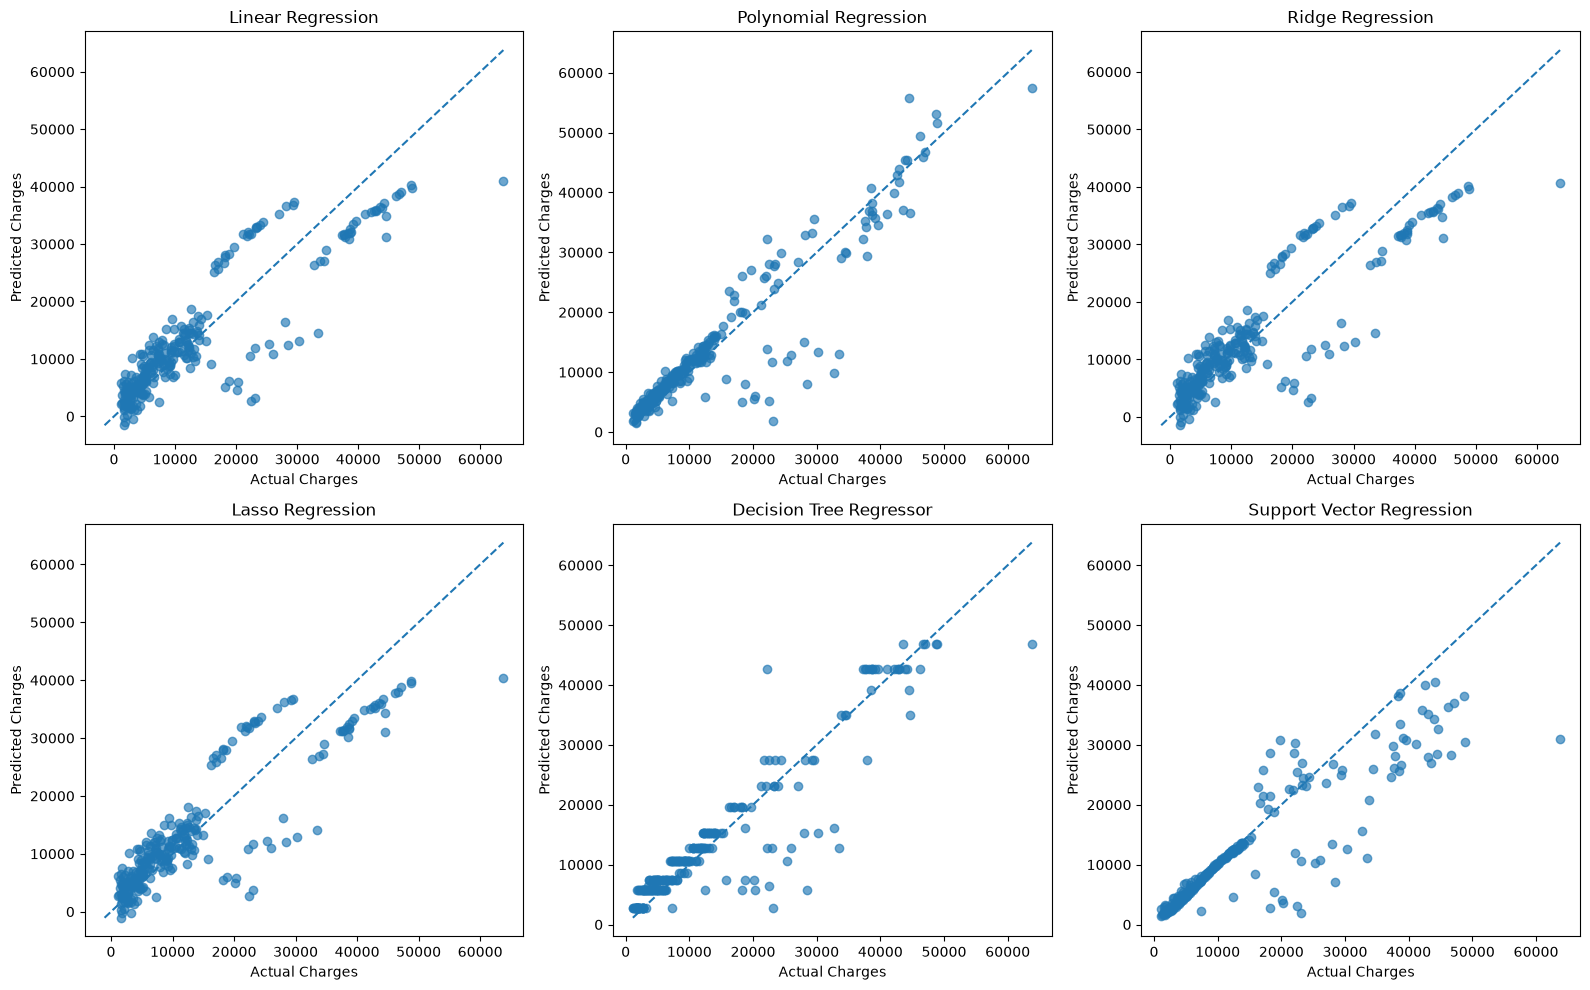

In [89]:
# Buat visualisasi perbandingan nilai aktual dan prediksi jika diperlukan.
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.ravel()

for ax, (model_name, y_pred) in zip(axes, predictions.items()):
    ax.scatter(y_test, y_pred, alpha=0.65)
    min_val = min(y_test.min(), y_pred.min())
    max_val = max(y_test.max(), y_pred.max())
    ax.plot([min_val, max_val], [min_val, max_val], "--")
    ax.set_title(model_name)
    ax.set_xlabel("Actual Charges")
    ax.set_ylabel("Predicted Charges")

plt.tight_layout()
plt.show()

# 5. Analisis

#### Bandingkan hasil Linear Regression, Polynomial Regression, Ridge, Lasso, Decision Tree Regressor, dan SVR berdasarkan metrik evaluasi. Jelaskan pengaruh preprocessing dan parameter yang digunakan terhadap hasil.


Dataset terdiri dari 1.338 baris dan 7 kolom. Seluruh kolom tidak memiliki missing value, dan terdapat 1 baris duplikat. Variabel kategorikal adalah `sex`, `smoker`, dan `region`, sedangkan `age`, `bmi`, `children`, dan `charges` bersifat numerik. Distribusi `charges` cukup lebar. Perbedaan biaya berdasarkan `smoker` juga terlihat jelas: rata-rata `charges` perokok sekitar 32.050,23, sedangkan non-perokok sekitar 8.434,27. Korelasi numerik terhadap `charges` paling besar terdapat pada `age` (0,299), diikuti `bmi` (0,198) dan `children` (0,068).

| Model | MAE | RMSE | R² |
|---|---:|---:|---:|
| Polynomial Regression (degree 2) | 2729,50 | **4551,13** | **0,8666** |
| Decision Tree Regressor (max_depth=4, min_samples_leaf=1) | **2697,77** | 4592,76 | 0,8641 |
| Linear Regression | 4181,19 | 5796,28 | 0,7836 |
| Ridge Regression (alpha=10) | 4187,36 | 5800,15 | 0,7833 |
| Lasso Regression (alpha≈115,54) | 4202,01 | 5831,85 | 0,7809 |
| Support Vector Regression (C=1000, gamma=scale, epsilon=0,1) | 2724,94 | 5955,62 | 0,7715 |

Berdasarkan RMSE dan R², **Polynomial Regression degree 2** memberikan performa terbaik pada data test. Decision Tree sangat dekat dan menghasilkan MAE paling kecil, tetapi RMSE dan R² sedikit lebih buruk daripada Polynomial Regression. Linear, Ridge, dan Lasso memberikan hasil yang sangat mirip. Pada eksperimen ini, regularisasi tidak memberi peningkatan berarti dibanding Linear Regression. SVR menghasilkan MAE yang cukup rendah, tetapi RMSE lebih tinggi dan R² paling rendah dari enam model yang diuji.

Untuk preprocessing, fitur kategorikal diproses menggunakan `OneHotEncoder`. Model Linear Regression, Polynomial Regression, Ridge, Lasso, dan SVR menggunakan `StandardScaler`, sedangkan Decision Tree tidak menggunakan scaling. Pada Polynomial Regression, fitur polynomial dibentuk terlebih dahulu lalu distandardisasi, mengikuti alur modul. Pemilihan degree dilakukan menggunakan validation set sehingga test set tetap hanya digunakan untuk evaluasi akhir. Ridge dan Lasso memilih `alpha` dengan cross-validation. Decision Tree memilih `max_depth` dan `min_samples_leaf` dari validation set, sedangkan SVR memilih `C`, `gamma`, dan `epsilon` dari validation set.

Hasil eksperimen Polynomial menunjukkan degree 2 memiliki validation RMSE terendah (5431,32), lebih baik daripada degree 3 (5508,43) dan degree 1 (6602,04). Hal ini menunjukkan bahwa peningkatan kompleksitas dari degree 1 ke 2 membantu menangkap pola non-linear, tetapi degree 3 tidak memberikan peningkatan pada validation set.

# 6. Kesimpulan dan Saran

#### Berikan kesimpulan berdasarkan hasil eksperimen. Saran dapat berupa perubahan parameter, preprocessing, atau eksperimen lanjutan.


Berdasarkan eksperimen pada Medical Cost Personal Dataset, **Polynomial Regression degree 2** merupakan model terbaik berdasarkan RMSE terkecil (4551,13) dan R² terbesar (0,8666). **Decision Tree Regressor** menjadi model kedua yang sangat dekat, dengan MAE paling kecil (2697,77), tetapi RMSE sedikit lebih besar (4592,76).

Linear Regression, Ridge, dan Lasso menghasilkan performa yang relatif sama pada dataset ini. Ridge memilih `alpha=10`, sedangkan Lasso memilih `alpha≈115,54`, tetapi regularisasi tersebut tidak meningkatkan hasil dibanding Linear Regression. SVR dengan RBF kernel memperoleh parameter terbaik `C=1000`, `gamma=scale`, dan `epsilon=0,1`; model ini memiliki MAE yang cukup baik tetapi RMSE dan R² lebih buruk dibanding Polynomial dan Decision Tree.

Preprocessing berperan penting karena fitur kategorikal harus diubah menjadi bentuk numerik menggunakan One-Hot Encoding, sedangkan model yang sensitif terhadap skala menggunakan StandardScaler. Eksperimen parameter dilakukan tanpa menggunakan test set untuk pemilihan model sehingga evaluasi akhir tetap dapat digunakan sebagai pengukuran performa pada data yang belum pernah dilihat.

Eksperimen berikutnya dapat mencoba transformasi target `charges`, memperluas pencarian hyperparameter, atau menggunakan cross-validation secara konsisten pada seluruh model untuk memperoleh estimasi performa yang lebih stabil.